In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

from config import Config

In [ ]:
print(f"Config.LMD_2022_PATH: {Config.LMD_2022_PATH}")

Config.LMD_2022_PATH: ../data/lmd2022/LMD-2022_NormalVsMalicious.csv


In [ ]:
df = pd.read_csv(Config.LMD_2022_PATH, low_memory=False)
useful_cols = [col for col in df.columns if not col.startswith('Unnamed')]
print(f"Useful columns (excluding Unnamed): {len(useful_cols)}")

Useful columns (excluding Unnamed): 94


In [ ]:
print(df['Label'].value_counts())
print("__________________ \n")
print(df['Label'].value_counts(normalize=True) * 100)

Label
1                          191194
0                          102354
0x5                           104
0x7                            12
0x3                             8
GetConfigurationOptions         1
172.217.18.10                   1
172.217.18.14                   1
142.250.186.170                 1
216.58.212.138                  1
142.250.184.206                 1
185.89.210.46                   1
Name: count, dtype: int64
__________________ 

Label
1                          65.103055
0                          34.852339
0x5                         0.035413
0x7                         0.004086
0x3                         0.002724
GetConfigurationOptions     0.000341
172.217.18.10               0.000341
172.217.18.14               0.000341
142.250.186.170             0.000341
216.58.212.138              0.000341
142.250.184.206             0.000341
185.89.210.46               0.000341
Name: proportion, dtype: float64


In [ ]:
lmd2022_df = df[useful_cols].copy()
lmd2022_df.rename(columns={'Label': 'isMalicious'}, inplace=True)
lmd2022_df = lmd2022_df[(lmd2022_df['isMalicious'] == '1') | (lmd2022_df['isMalicious'] == '0')].copy()
lmd2022_df['isMalicious'].value_counts()

isMalicious
1    191194
0    102354
Name: count, dtype: int64

In [ ]:
len (lmd2022_df.columns.tolist())

94

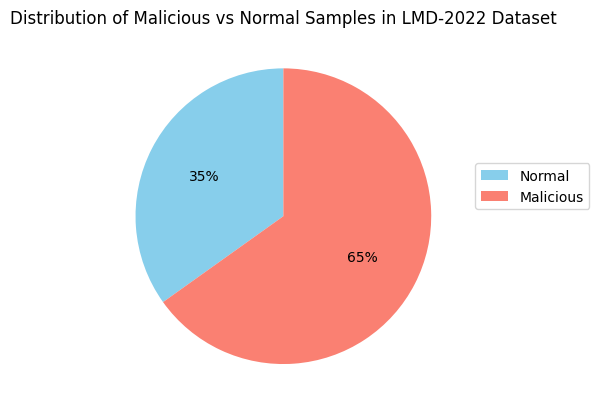

In [ ]:
counts = lmd2022_df['isMalicious'].value_counts().sort_index()
fig, ax = plt.subplots()
counts.plot(kind='pie', colors=['skyblue', 'salmon'], autopct='%1.0f%%',startangle=90, ax=ax,labels=['', ''])
ax.set_title('Distribution of Malicious vs Normal Samples in LMD-2022 Dataset')
ax.legend(['Normal', 'Malicious'], loc='lower left', bbox_to_anchor=(1, 0.5))
ax.set_ylabel('')
plt.show()

In [ ]:
# Sysmon Event ID Mapping
sorted(lmd2022_df['EventID'].unique().tolist())
event_mapping = {
    1: 'Process Creation',
    2: 'File Creation Time Changed',
    3: 'Network Connection',
    4: 'Sysmon Service State Changed',
    5: 'Process Terminated',
    6: 'Driver Loaded',
    7: 'Image Loaded',
    8: 'CreateRemoteThread',
    10: 'ProcessAccess',
    11: 'FileCreate',
    12: 'RegistryEvent (Create/Delete)',
    13: 'RegistryEvent (Value Set)',
    15: 'FileCreateStreamHash',
    16: 'Sysmon Config Changed',
    17: 'PipeEvent (Created)',
    18: 'PipeEvent (Connected)',
    22: 'DNSEvent',
    23: 'FileDelete',
    255: 'Error'
}

events_info = lmd2022_df[['EventID', 'isMalicious']]
events_info['EventName'] = events_info['EventID'].map(event_mapping)

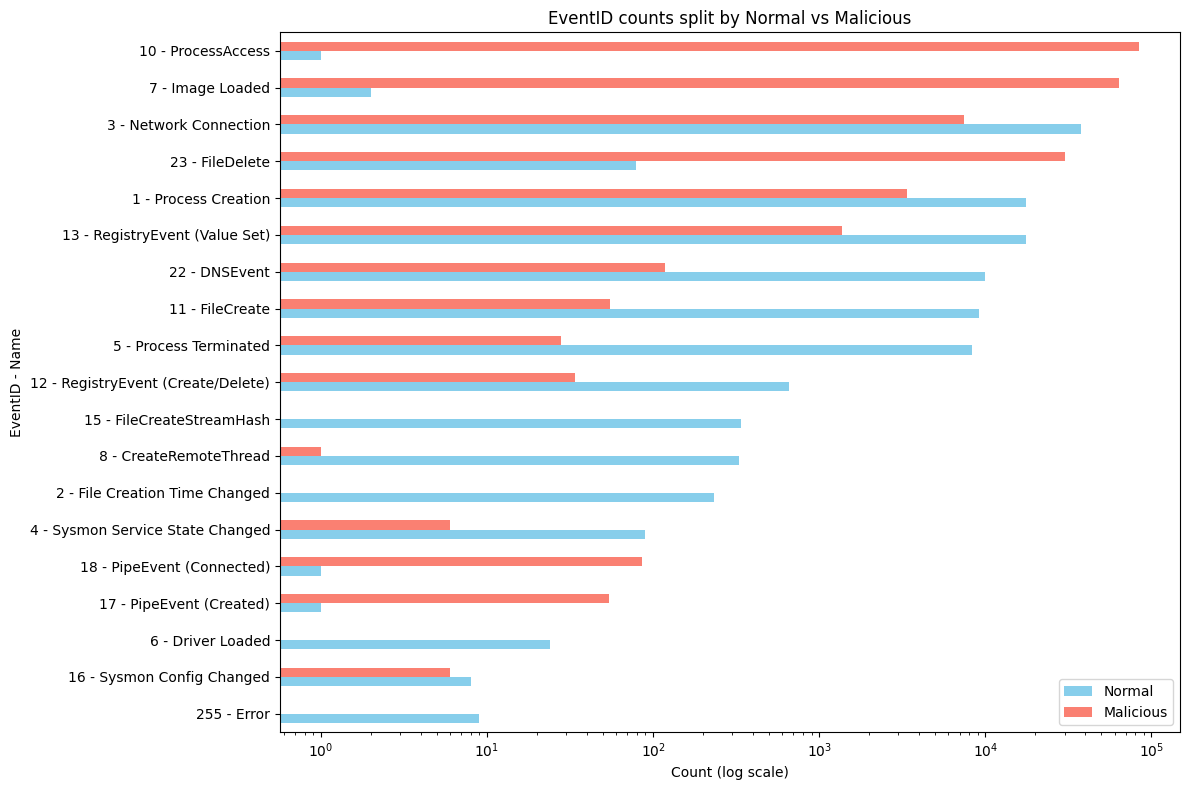

In [ ]:
counts = events_info.groupby(['EventID', 'isMalicious']).size().unstack(fill_value=0)
counts.columns = ['Normal', 'Malicious']
counts['Total'] = counts.sum(axis=1)
counts = counts.sort_values('Total').drop(columns='Total')

new_index = []

for eid in counts.index:
    if eid in event_mapping:
        event_name = event_mapping[eid]
    else:
        event_name = ''
    label = str(eid) + ' - ' + event_name
    new_index.append(label)

counts.index = new_index

counts.plot.barh(figsize=(12, 8), color=['skyblue', 'salmon'])
plt.xscale('log')
plt.xlabel('Count (log scale)')
plt.ylabel('EventID - Name')
plt.title('EventID counts split by Normal vs Malicious')
plt.tight_layout()
plt.show()

# 06/02
# Feature selection
# Create dataset for feature selection and importance using Random forest
# Create a and run random foreset
# Create chart

In [ ]:
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.model_selection import train_test_split


In [ ]:
# Identify columns with >99.9% single value , which are unlikely to be useful for modeling
not_useful_cols = []
for col in lmd2022_df.columns:
    top_freq = lmd2022_df[col].value_counts(normalize=True).iloc[0]
    if top_freq > 0.999:
        not_useful_cols.append(col)
        print(f"  {col}: {top_freq:.4%} single value")


  Name: 100.0000% single value
  Level: 99.9969% single value
  Opcode: 100.0000% single value
  Keywords: 100.0000% single value
  Correlation: 100.0000% single value
  Execution_ProcessID: 100.0000% single value
  Channel: 100.0000% single value
  UserID: 99.9952% single value
  State: 99.9847% single value
  Version2: 99.9850% single value
  SchemaVersion: 99.9847% single value
  Configuration: 99.9983% single value
  ConfigurationFileHash: 99.9983% single value
  PipeName: 99.9523% single value
  ID: 99.9843% single value


In [ ]:
not_useful_cols

# Columns to drop based on Christos Smiliotopoulos, plus some additional ones that are unlikely to be useful for modeling because they have the same value for all rows
addtional_cols_to_drop = [
    'Name',
    'Guid',
    'Opcode',
    'Keywords',
    'Correlation',
    'Channel',
    'State',
    'Version',
    'StartFunction',
    'ID'
]

for col in addtional_cols_to_drop:
    if col not in not_useful_cols:
        not_useful_cols.append(col)

len(not_useful_cols)

18

In [ ]:
lmd2022_df = lmd2022_df.drop(columns=not_useful_cols)
len(lmd2022_df.columns)

76

In [ ]:
X = lmd2022_df.drop(columns=['isMalicious'])
y = lmd2022_df['isMalicious']

X.dtypes

EventID                    int64
Task                       int64
SystemTime                   str
EventRecordID              int64
ProcessID                  int64
                           ...  
StartAddress                 str
StartModule                  str
PreviousCreationUtcTime      str
Hash                         str
Contents                     str
Length: 75, dtype: object

In [ ]:
pd.DataFrame(X.dtypes.unique().tolist())

,0
0,int64
1,str
2,float64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler

# 1. Setup
X_stats = X.copy()

categorical_cols = X_stats.columns  

chi_scores = pd.DataFrame()
X_col = X_stats[categorical_cols].copy()

# Handle missing values by filling with a placeholder (Chi2 cannot handle NaNs)
X_col = X_col.fillna("Unknown_Category")

# Encode Strings to Numbers
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_col[X_col.columns] = encoder.fit_transform(X_col)

# Ensure Non-Negative (Chi2 requires numbers >= 0)
scaler = MinMaxScaler()
X_cat_scaled = scaler.fit_transform(X_col)

# Run Chi-Square
selector_chi = SelectKBest(score_func=chi2, k='all')
selector_chi.fit(X_cat_scaled, y.loc[X_col.index])

chi_scores = pd.DataFrame({
    'Feature': categorical_cols,
    'Score': selector_chi.scores_,
})

final_results = chi_scores.sort_values(by='Score', ascending=False)

print(final_results.head(20))

              Feature         Score
11              Image  79783.688647
30           Protocol  46240.752777
32       SourceIsIpv6  34952.651308
37  DestinationIsIpv6  34952.651308
19               User  34823.219089
9         ProcessGuid  34489.403437
43             Signed  34174.634037
45    SignatureStatus  34174.634037
53      GrantedAccess  32362.674003
50  TargetProcessGUID  31308.114740
46  SourceProcessGUID  29984.370070
59          EventType  28732.662632
31          Initiated  28406.998663
52        TargetImage  27446.697862
49        SourceImage  27296.114979
2          SystemTime  26560.005646
7            RuleName  26466.903314
47    SourceProcessId  25080.751567
33           SourceIp  24800.712260
3       EventRecordID  23906.244868


To keep 95.0% of the information, you need 45 features.


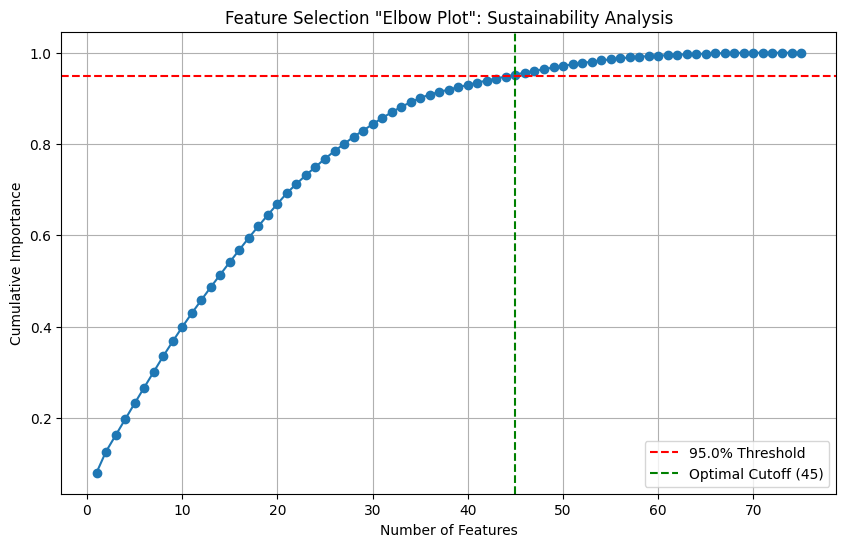

Your Sustainable Feature Set:
<StringArray>
[              'Image',            'Protocol',        'SourceIsIpv6',
   'DestinationIsIpv6',                'User',         'ProcessGuid',
              'Signed',     'SignatureStatus',       'GrantedAccess',
   'TargetProcessGUID',   'SourceProcessGUID',           'EventType',
           'Initiated',         'TargetImage',         'SourceImage',
          'SystemTime',            'RuleName',     'SourceProcessId',
            'SourceIp',       'EventRecordID',            'Computer',
       'DestinationIp',      'SourceThreadId',    'CurrentDirectory',
      'IntegrityLevel',     'TargetProcessId',         'ImageLoaded',
     'DestinationPort',           'CallTrace',     'ParentProcessId',
        'TargetObject',         'ParentImage',            'Archived',
     'CreationUtcTime',           'LogonGuid', 'DestinationPortName',
            'ThreadID',             'LogonId',      'SourcePortName',
   'ParentProcessGuid',           'Signature',

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Get your scores from the previous step
feature_importance_df = final_results.sort_values(by='Score', ascending=False)

# 2. Normalize scores so they add up to 1.0 (100%)
total_score = feature_importance_df['Score'].sum()
feature_importance_df['Normalized_Score'] = feature_importance_df['Score'] / total_score

# 3. Calculate Cumulative Sum
feature_importance_df['Cumulative_Score'] = feature_importance_df['Normalized_Score'].cumsum()

# 4. Find the cut-off (e.g., 95% of information)
cutoff_threshold = 0.95
optimal_features = feature_importance_df[feature_importance_df['Cumulative_Score'] <= cutoff_threshold]
num_features_to_keep = len(optimal_features) + 1 # Add 1 because the cutoff usually drops the one that crosses the line

print(f"To keep {cutoff_threshold*100}% of the information, you need {num_features_to_keep} features.")

# 5. Plot it
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(feature_importance_df) + 1), feature_importance_df['Cumulative_Score'], marker='o')
plt.axhline(y=cutoff_threshold, color='r', linestyle='--', label=f'{cutoff_threshold*100}% Threshold')
plt.axvline(x=num_features_to_keep, color='g', linestyle='--', label=f'Optimal Cutoff ({num_features_to_keep})')
plt.title('Feature Selection "Elbow Plot": Sustainability Analysis')
plt.xlabel('Number of Features')
plt.ylabel('Cumulative Importance')
plt.legend()
plt.grid(True)
plt.show()

# Print the winners
print("Your Sustainable Feature Set:")
print(feature_importance_df['Feature'].head(num_features_to_keep).values)

Force-encoding these columns: ['Image', 'Protocol', 'SourceIsIpv6', 'DestinationIsIpv6', 'User', 'ProcessGuid', 'Signed', 'SignatureStatus', 'GrantedAccess', 'TargetProcessGUID', 'SourceProcessGUID', 'EventType', 'Initiated', 'TargetImage', 'SourceImage', 'SystemTime', 'RuleName', 'SourceIp', 'Computer', 'DestinationIp', 'CurrentDirectory', 'IntegrityLevel', 'ImageLoaded', 'CallTrace', 'ParentProcessId', 'TargetObject', 'ParentImage', 'Archived', 'CreationUtcTime', 'LogonGuid', 'DestinationPortName', 'LogonId', 'SourcePortName', 'ParentProcessGuid', 'Signature', 'Hashes', 'IsExecutable']


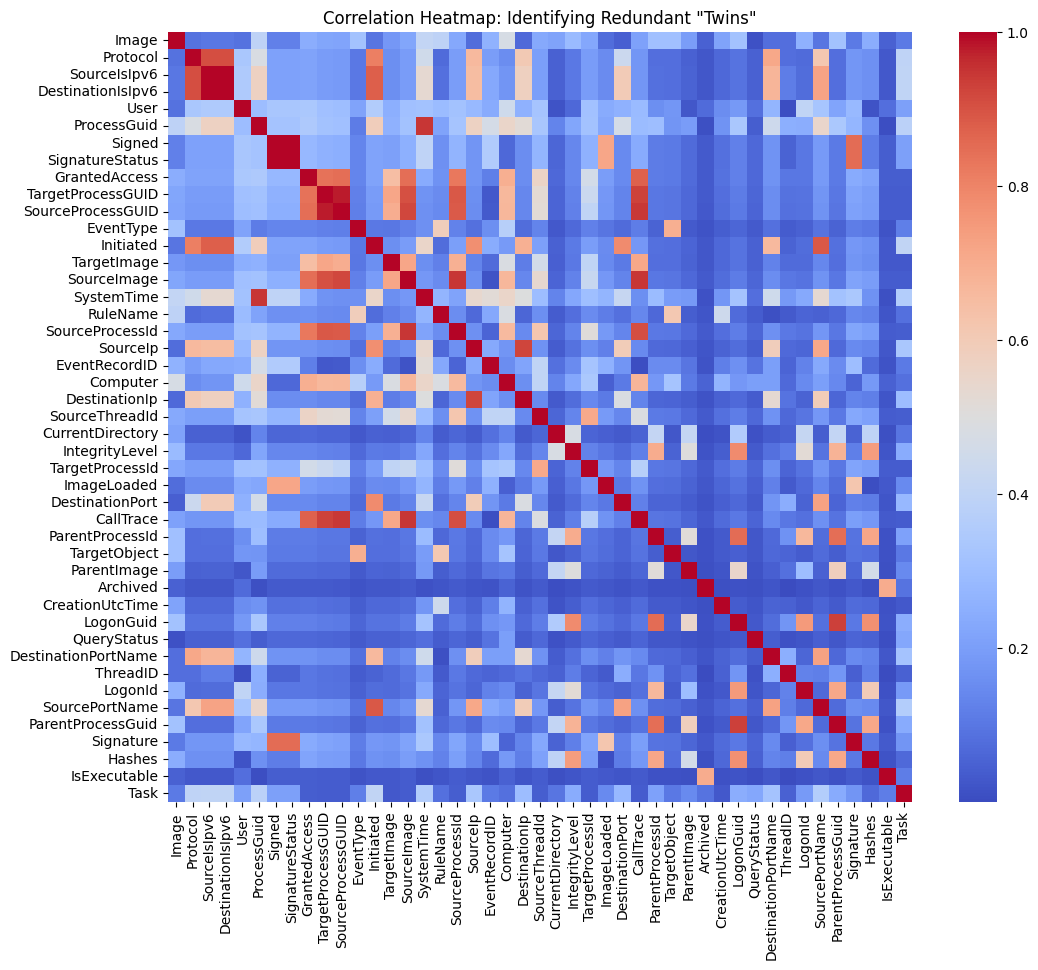

Detected 10 redundant features.
Dropping: ['SourceIsIpv6', 'DestinationIsIpv6', 'SignatureStatus', 'SourceProcessGUID', 'SourceImage', 'SystemTime', 'SourceProcessId', 'DestinationIp', 'CallTrace', 'ParentProcessGuid']
Final Feature Count: 35


In [ ]:

top_features_list = feature_importance_df['Feature'].head(num_features_to_keep).values
X_final = X[top_features_list].copy()

# --- STEP 2: THE NUCLEAR ENCODER ---
X_corr_calc = X_final.copy()

# Identify ALL non-numeric columns (Strings, Objects, Categories, Dates)
non_numeric_cols = X_corr_calc.select_dtypes(exclude=['number']).columns

print(f"Force-encoding these columns: {list(non_numeric_cols)}")

# Factorize them all
for col in non_numeric_cols:
    # pd.factorize returns a tuple (codes, uniques), we only want the codes [0]
    X_corr_calc[col] = pd.factorize(X_corr_calc[col])[0]

# --- STEP 3: CALCULATE CORRELATION ---
corr_matrix = X_corr_calc.corr().abs()

# Plot (Optional)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title('Correlation Heatmap: Identifying Redundant "Twins"')
plt.show()

# --- STEP 4: IDENTIFY & DROP TWINS ---
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]

print(f"Detected {len(to_drop)} redundant features.")
print("Dropping:", to_drop)

# --- STEP 5: FINAL CLEANUP ---
X_reduced = X_final.drop(columns=to_drop)
print(f"Final Feature Count: {X_reduced.shape[1]}")

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# We work on a copy to avoid warnings
X_rfe_input = X_reduced.copy()

# Force-Encode ALL non-numeric columns to numbers
non_numeric_cols = X_rfe_input.select_dtypes(exclude=['number']).columns

if len(non_numeric_cols) > 0:
    #print(f"Encoding {len(non_numeric_cols)} text columns for RFE: {list(non_numeric_cols)}")
    for col in non_numeric_cols:
        X_rfe_input[col] = pd.factorize(X_rfe_input[col])[0]
else:
    print("Data is already numeric. Proceeding...")

# We use a fast Random Forest (50 trees)
rf_rfe = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)

# We want to select the top 15 features
selector = RFE(estimator=rf_rfe, n_features_to_select=15, step=1)

print("Starting RFE... (This forces the model to re-train 20 times, please wait)")

# --- STEP 3: RUN RFE ---
# Now we pass the fully numeric X_rfe_input
selector.fit(X_rfe_input, y.loc[X_rfe_input.index])

# --- STEP 4: GET THE SURVIVORS ---v
selected_features = X_rfe_input.columns[selector.support_]

print(f"\nSUCCESS! The Final 15 Features are:\n{list(selected_features)}")

Encoding 28 text columns for RFE: ['Image', 'Protocol', 'User', 'ProcessGuid', 'Signed', 'GrantedAccess', 'TargetProcessGUID', 'EventType', 'Initiated', 'TargetImage', 'RuleName', 'SourceIp', 'Computer', 'CurrentDirectory', 'IntegrityLevel', 'ImageLoaded', 'ParentProcessId', 'TargetObject', 'ParentImage', 'Archived', 'CreationUtcTime', 'LogonGuid', 'DestinationPortName', 'LogonId', 'SourcePortName', 'Signature', 'Hashes', 'IsExecutable']
Starting RFE... (This forces the model to re-train 20 times, please wait)

SUCCESS! The Final 15 Features are:
['Image', 'User', 'ProcessGuid', 'TargetProcessGUID', 'RuleName', 'SourceIp', 'EventRecordID', 'Computer', 'ImageLoaded', 'CreationUtcTime', 'ThreadID', 'SourcePortName', 'Hashes', 'IsExecutable', 'Task']


In [ ]:
selected_features

Index(['Image', 'User', 'ProcessGuid', 'TargetProcessGUID', 'RuleName',
       'SourceIp', 'EventRecordID', 'Computer', 'ImageLoaded',
       'CreationUtcTime', 'ThreadID', 'SourcePortName', 'Hashes',
       'IsExecutable', 'Task'],
      dtype='str')

In [ ]:
X = X[selected_features].copy()

In [ ]:
X.info()

<class 'pandas.DataFrame'>
Index: 293548 entries, 0 to 293678
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Image              293548 non-null  str  
 1   User               293548 non-null  str  
 2   ProcessGuid        293548 non-null  str  
 3   TargetProcessGUID  293548 non-null  str  
 4   RuleName           293548 non-null  str  
 5   SourceIp           293548 non-null  str  
 6   EventRecordID      293548 non-null  int64
 7   Computer           293548 non-null  str  
 8   ImageLoaded        293548 non-null  str  
 9   CreationUtcTime    293548 non-null  str  
 10  ThreadID           293548 non-null  int64
 11  SourcePortName     293548 non-null  str  
 12  Hashes             293548 non-null  str  
 13  IsExecutable       289162 non-null  str  
 14  Task               293548 non-null  int64
dtypes: int64(3), str(12)
memory usage: 43.9 MB


In [ ]:
not_Usesful_col = ['EventRecordID', 'CreationUtcTime', 'ThreadID']
X.drop(columns=not_Usesful_col, inplace=True)

In [ ]:
X.info()

<class 'pandas.DataFrame'>
Index: 293548 entries, 0 to 293678
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Image              293548 non-null  str  
 1   User               293548 non-null  str  
 2   ProcessGuid        293548 non-null  str  
 3   TargetProcessGUID  293548 non-null  str  
 4   RuleName           293548 non-null  str  
 5   SourceIp           293548 non-null  str  
 6   Computer           293548 non-null  str  
 7   ImageLoaded        293548 non-null  str  
 8   SourcePortName     293548 non-null  str  
 9   Hashes             293548 non-null  str  
 10  IsExecutable       289162 non-null  str  
 11  Task               293548 non-null  int64
dtypes: int64(1), str(11)
memory usage: 37.2 MB


In [ ]:
X.head()